# PASMO Radar Dataset Exploration


## 0. Imports

In [186]:
import numpy as np
import statsmodels.api as sm

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

## 1. Data review

In [187]:
data_path = Path("..//data//raw//pasmo_dataset.csv")

In [188]:
df = pd.read_csv(data_path).drop(columns=["Unnamed: 0"])
df.head()

,year,month,day,hour,minute,wd,speed_med_AR3,speed_med_DR3,speed_med_AR2,speed_med_DR2,...,speed_max_AR1,speed_max_DR1,speed_min_AR3,speed_min_DR3,speed_min_AR2,speed_min_DR2,speed_min_AR1,speed_min_DR1,TF_barra,TF_costa
0,2020,1,1,0,0,2,0.0,0.0,0.0,0.0,...,121.306837,182.024905,0.0,0.0,0.0,0.0,49.754164,29.679659,-2.0,0.0
1,2020,1,1,0,10,2,0.0,0.0,0.0,0.0,...,121.306837,182.024905,0.0,0.0,0.0,0.0,49.754164,29.679659,-2.0,0.0
2,2020,1,1,0,20,2,0.0,0.0,0.0,0.0,...,121.306837,182.024905,0.0,0.0,0.0,0.0,49.754164,29.679659,-2.0,0.0
3,2020,1,1,0,30,2,0.0,0.0,0.0,0.0,...,121.306837,182.024905,0.0,0.0,0.0,0.0,49.754164,29.679659,-2.0,0.0
4,2020,1,1,0,40,2,0.0,0.0,0.0,0.0,...,121.306837,182.024905,0.0,0.0,0.0,0.0,49.754164,29.679659,-2.0,0.0


Is there a missing data? What data types are there? What is the range of values?

In [189]:
N, M = len(df), len(df.columns)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 74305 entries, 0 to 74304
Data columns (total 26 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           74305 non-null  int64  
 1   month          74305 non-null  int64  
 2   day            74305 non-null  int64  
 3   hour           74305 non-null  int64  
 4   minute         74305 non-null  int64  
 5   wd             74305 non-null  int64  
 6   speed_med_AR3  74305 non-null  float64
 7   speed_med_DR3  74305 non-null  float64
 8   speed_med_AR2  74305 non-null  float64
 9   speed_med_DR2  74305 non-null  float64
 10  speed_med_AR1  74305 non-null  float64
 11  speed_med_DR1  74305 non-null  float64
 12  speed_max_AR3  74305 non-null  float64
 13  speed_max_DR3  74305 non-null  float64
 14  speed_max_AR2  74305 non-null  float64
 15  speed_max_DR2  74305 non-null  float64
 16  speed_max_AR1  74305 non-null  float64
 17  speed_max_DR1  74305 non-null  float64
 18  speed_min_AR3  74

In [190]:
df.describe()

,year,month,day,hour,minute,wd,speed_med_AR3,speed_med_DR3,speed_med_AR2,speed_med_DR2,...,speed_max_AR1,speed_max_DR1,speed_min_AR3,speed_min_DR3,speed_min_AR2,speed_min_DR2,speed_min_AR1,speed_min_DR1,TF_barra,TF_costa
count,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,...,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000,74305.000000
mean,2020.290707,5.492241,15.688191,11.499845,24.999664,3.009649,28.203235,21.994143,35.263121,27.496317,...,99.492003,103.071689,9.193653,7.283574,13.599512,7.236658,13.434876,10.909582,0.199273,-3.617839
std,0.454092,3.402852,8.776995,6.922315,17.078498,1.997583,24.856828,22.707260,24.834655,21.820967,...,52.837303,54.411899,15.357824,14.882276,18.271660,14.882615,19.636317,17.993663,20.299620,14.456468
min,2020.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-187.000000,-133.000000
25%,2020.000000,3.000000,8.000000,5.000000,10.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,82.083155,90.731431,0.000000,0.000000,0.000000,0.000000,0.720000,0.000000,-7.000000,-8.000000
50%,2020.000000,5.000000,16.000000,11.000000,20.000000,3.000000,29.184901,15.286655,48.586970,30.635756,...,118.804909,120.613432,0.360000,0.000000,1.484318,0.000000,3.600000,0.000000,0.000000,-0.888889
75%,2021.000000,8.000000,23.000000,17.000000,40.000000,5.000000,50.321395,42.771299,54.500120,46.604793,...,132.124417,133.920000,14.400000,3.240000,27.778379,3.758510,19.995400,14.799460,9.000000,2.000000
max,2021.000000,12.000000,31.000000,23.000000,50.000000,6.000000,131.760000,129.964482,250.000000,153.546086,...,250.000000,250.000000,131.760000,129.964482,125.039765,96.174592,189.725468,160.579769,155.000000,109.000000


In [191]:
columns = df.columns
timestamp_columns = ["year", "month", "day", "hour", "minute"]
speed_columns = [col for col in columns if "speed" in col]
speed_med_columns = [col for col in speed_columns if "med" in col]
tf_columns = [col for col in columns if col.startswith("TF")]

Is there a gaps in the data?

In [192]:
df["timestamp"] = pd.to_datetime(df[timestamp_columns])
df = df.sort_values("timestamp")
df["timestamp"].head()

0   2020-01-01 00:00:00
1   2020-01-01 00:10:00
2   2020-01-01 00:20:00
3   2020-01-01 00:30:00
4   2020-01-01 00:40:00
Name: timestamp, dtype: datetime64[us]

In [193]:
# time range
print(f"First timestamp: {df["timestamp"].min()}")
print(f"Last timestamp: {df["timestamp"].max()}")
print(f"Total rows: {N}")

First timestamp: 2020-01-01 00:00:00
Last timestamp: 2021-05-31 00:00:00
Total rows: 74305


In [194]:
gaps = df["timestamp"].diff().dropna()
intrv_gt_10m = (gaps > pd.Timedelta(minutes=10)).sum()
print(f"\nIntervals longer than 10 minutes: {intrv_gt_10m}")


Intervals longer than 10 minutes: 0


What is the encoding order of `wd`?

In [195]:
df.groupby("wd")["timestamp"].apply(
    lambda x: x.dt.day_name().value_counts()
)

wd           
0   Monday       10513
1   Tuesday      10512
2   Wednesday    10656
3   Thursday     10656
4   Friday       10656
5   Saturday     10656
6   Sunday       10656
Name: timestamp, dtype: int64

## 2. Exploratory Data Analysis (EDA)

### 2.0 Convert to Long Format: Selecting Median Speed for Visualization

In [196]:
df_long = df.melt(
    id_vars=timestamp_columns + tf_columns + ["timestamp", "wd"],
    value_vars=speed_columns,
    var_name="variable",
    value_name="value",
)
df_long.head()

,year,month,day,hour,minute,TF_barra,TF_costa,timestamp,wd,variable,value
0,2020,1,1,0,0,-2.0,0.0,2020-01-01 00:00:00,2,speed_med_AR3,0.0
1,2020,1,1,0,10,-2.0,0.0,2020-01-01 00:10:00,2,speed_med_AR3,0.0
2,2020,1,1,0,20,-2.0,0.0,2020-01-01 00:20:00,2,speed_med_AR3,0.0
3,2020,1,1,0,30,-2.0,0.0,2020-01-01 00:30:00,2,speed_med_AR3,0.0
4,2020,1,1,0,40,-2.0,0.0,2020-01-01 00:40:00,2,speed_med_AR3,0.0


In [197]:
df_med_long = df_long[df_long["variable"].isin(speed_med_columns)]

### 2.1 Distribution analysis

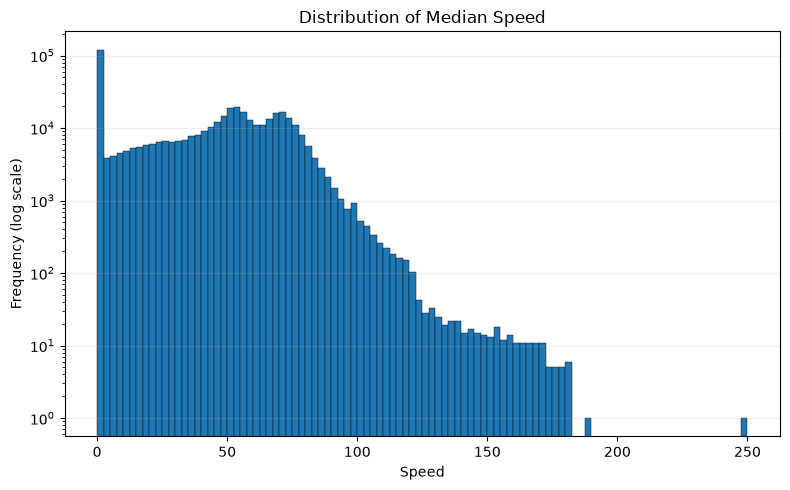

In [198]:
speed = df_med_long["value"].to_numpy()

plt.figure(figsize=(8, 5))
plt.hist(speed, bins=100, edgecolor="black", linewidth=0.3)
plt.yscale("log")
plt.title("Distribution of Median Speed")
plt.xlabel("Speed")
plt.ylabel("Frequency (log scale)")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

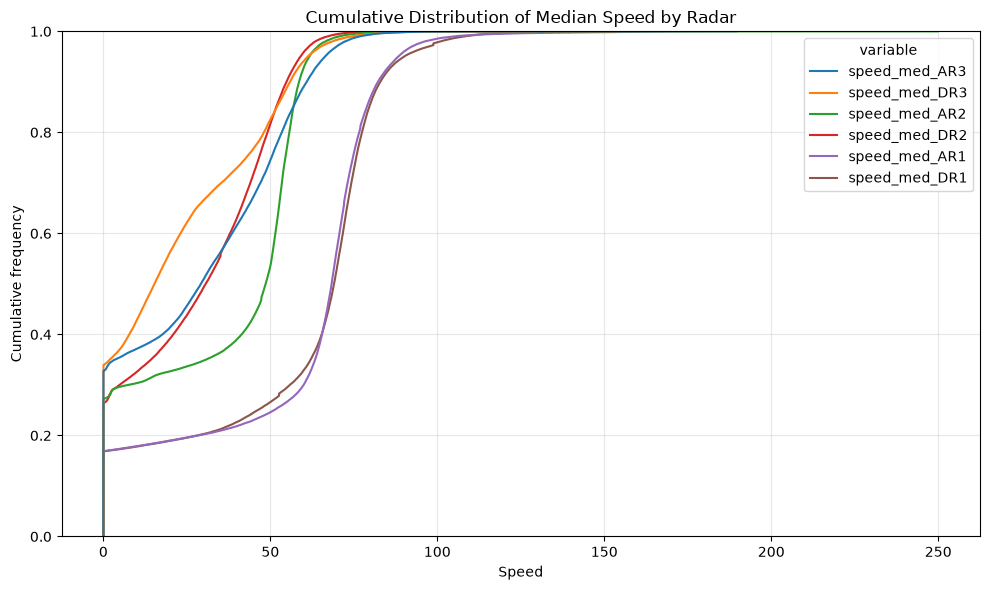

In [199]:
plt.figure(figsize=(10, 6))

sns.ecdfplot(
    data=df_med_long,
    x="value",
    hue="variable",
)

plt.title("Cumulative Distribution of Median Speed by Radar")
plt.xlabel("Speed")
plt.ylabel("Cumulative frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

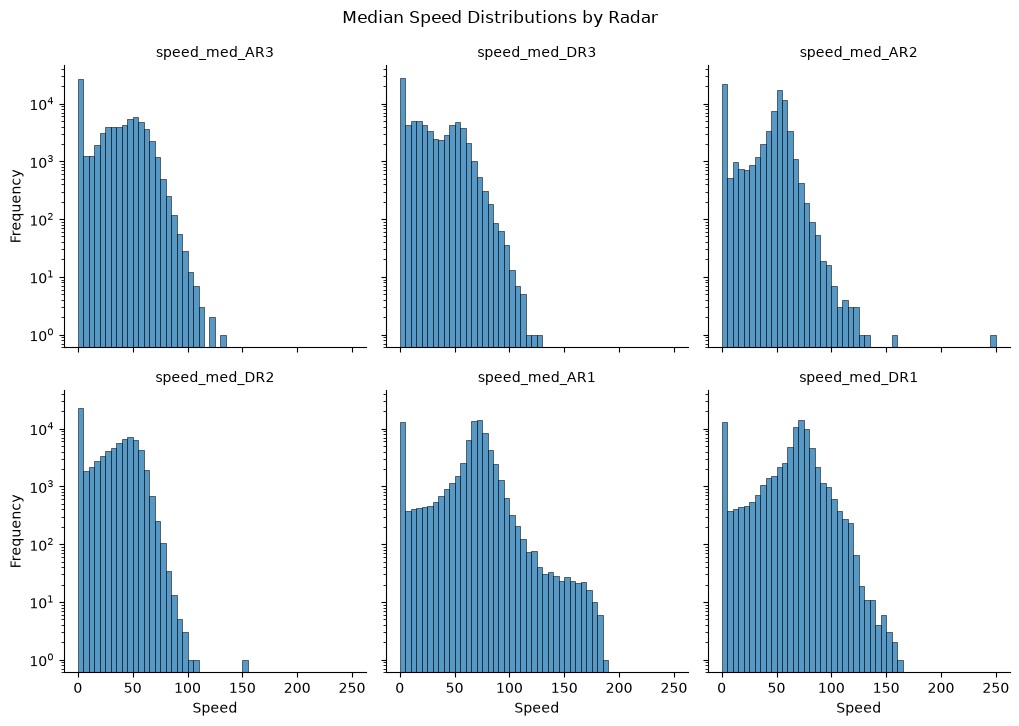

In [200]:
g = sns.displot(
    data=df_med_long,
    x="value",
    col="variable",
    col_wrap=3,
    bins=50,
    height=3.5,
)

g.set_axis_labels("Speed", "Frequency")
g.set_titles("{col_name}")
g.set(yscale="log")
g.figure.suptitle("Median Speed Distributions by Radar", y=1.03)
plt.show()

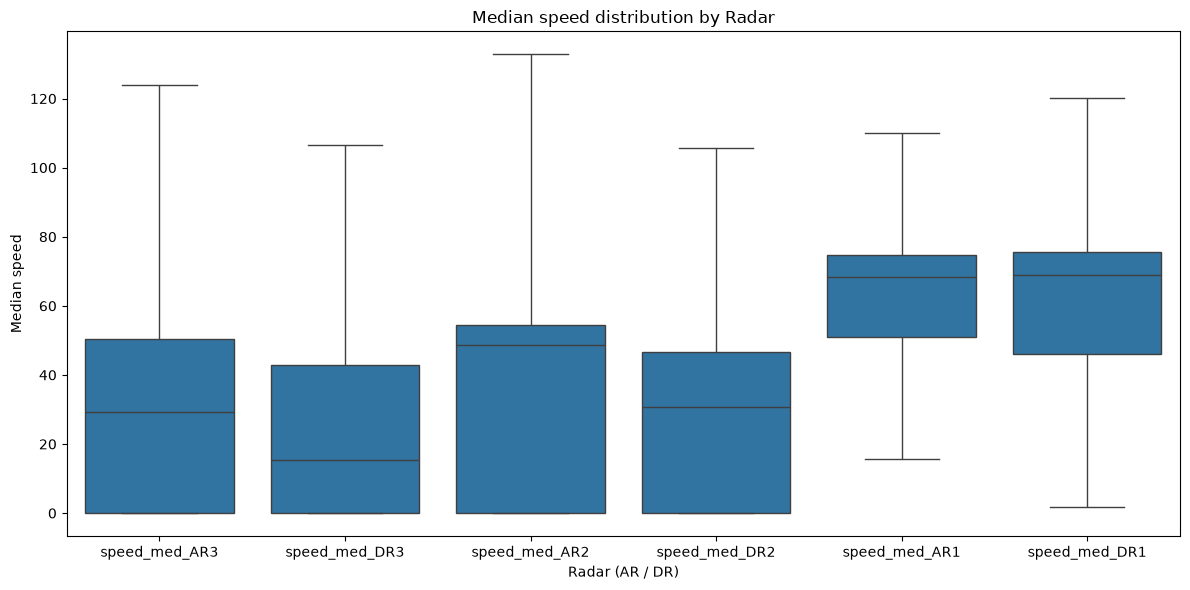

In [201]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_med_long,
    x="variable",
    y="value",
    showfliers=False,
)
plt.title("Median speed distribution by Radar")
plt.xlabel("Radar (AR / DR)")
plt.ylabel("Median speed")
plt.tight_layout()
plt.show()

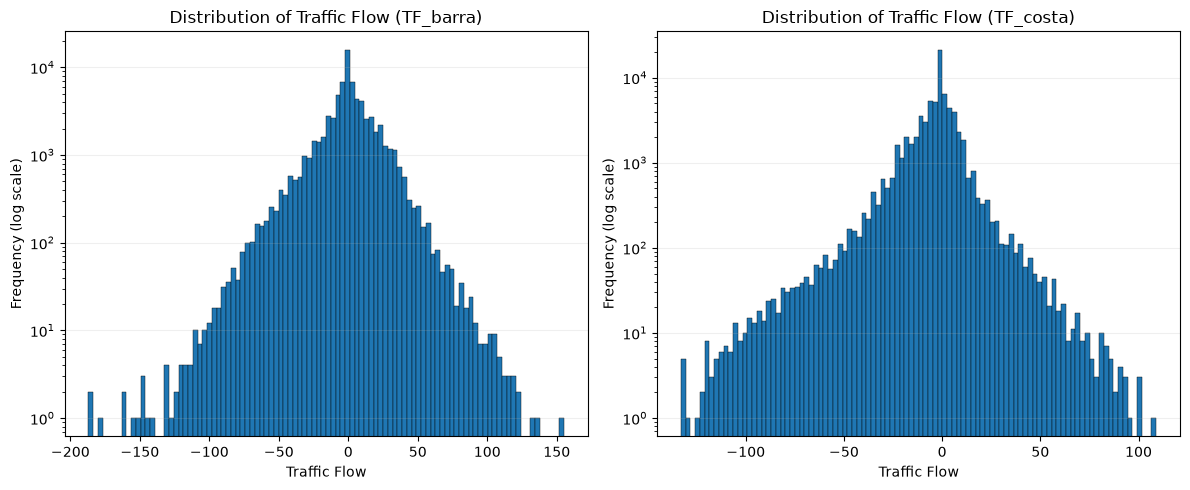

In [202]:
fig, axes = plt.subplots(1, len(tf_columns), figsize=(12, 5))

for i, ax in enumerate(axes):
    col = tf_columns[i]
    ax.hist(df[col], bins=100, edgecolor="black", linewidth=0.3, label=col)

    ax.set_title(f"Distribution of Traffic Flow ({col})")
    ax.set_xlabel("Traffic Flow")
    ax.set_ylabel("Frequency (log scale)")
    ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

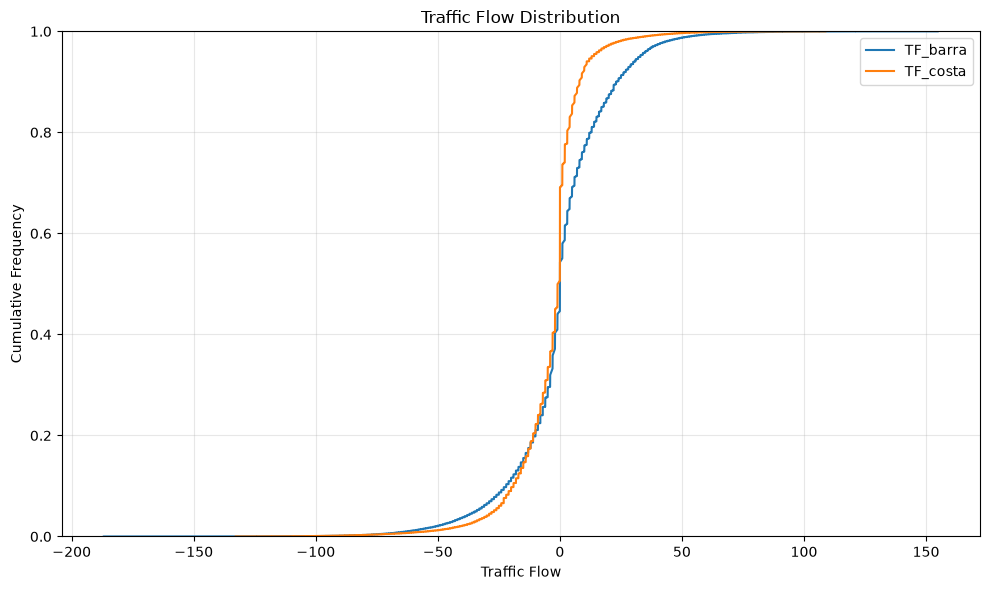

In [203]:
fig, ax = plt.subplots(figsize=(10, 6))

for col in tf_columns:
    sns.ecdfplot(
        data=df_med_long,
        x=col,
        ax=ax,
        legend=False,
        label=col,
    )

ax.set_title("Traffic Flow Distribution")
ax.set_xlabel("Traffic Flow")
ax.set_ylabel("Cumulative Frequency")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

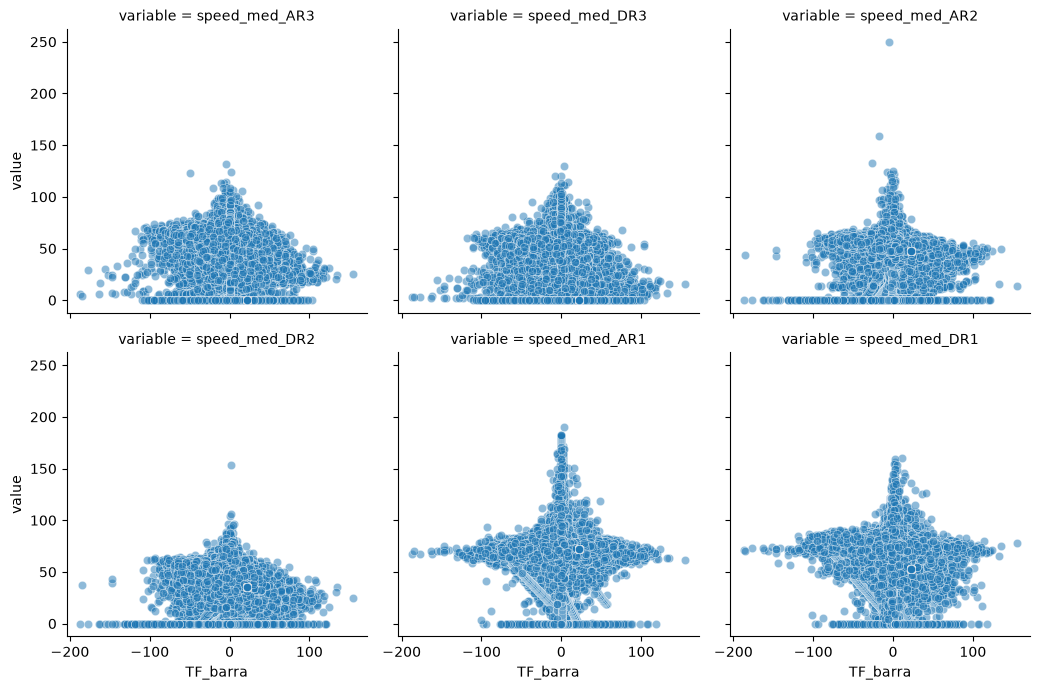

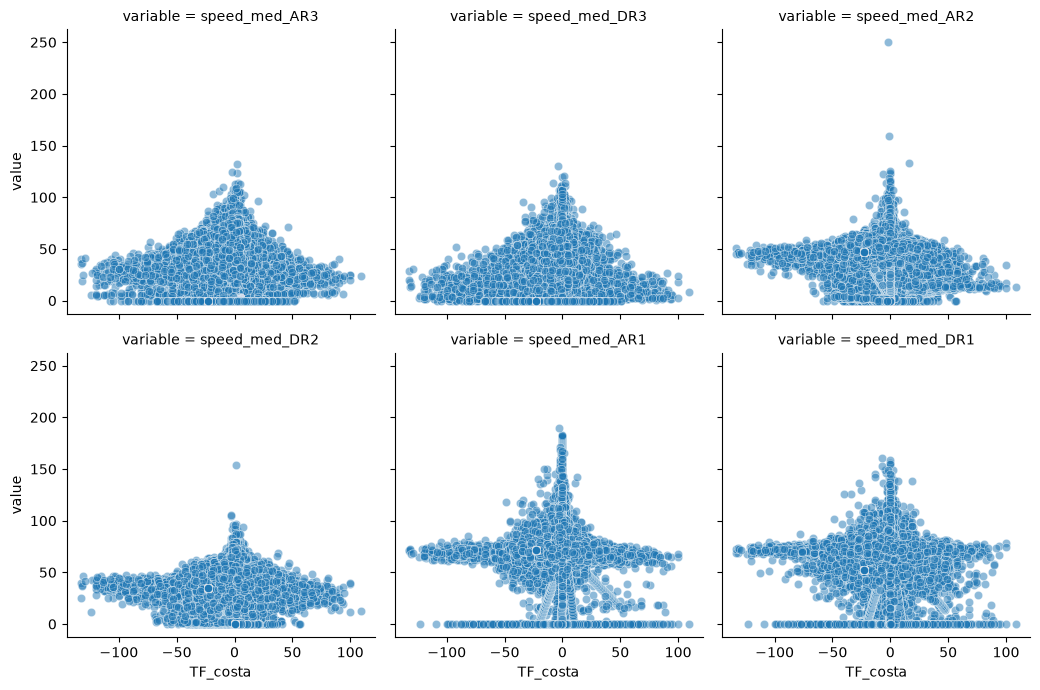

In [204]:
for i in range(len(tf_columns)):
    sns.relplot(
        data=df_med_long,
        x=tf_columns[i],
        y="value",
        col="variable",
        kind="scatter",
        col_wrap=3,
        alpha=0.5,
        height=3.5,
    )
    plt.show()

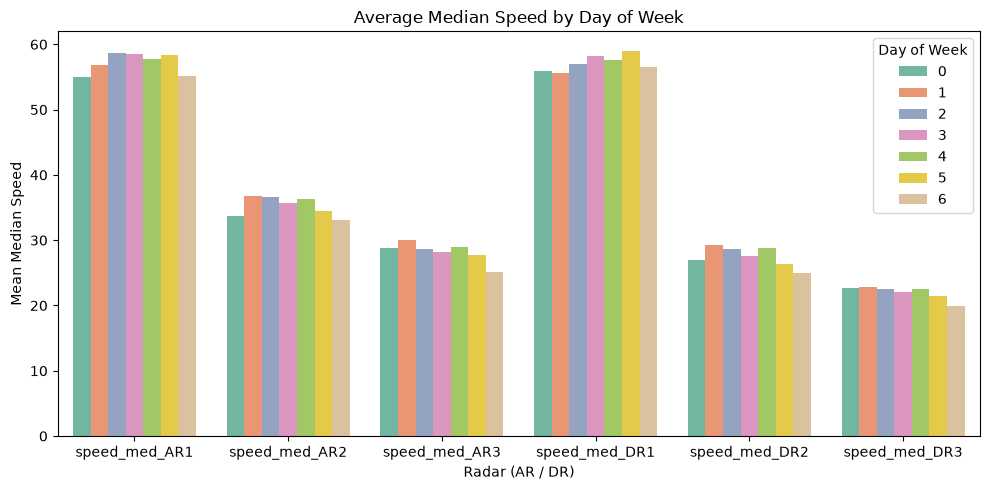

In [205]:
wd_summary = (
    df_med_long.groupby(["wd", "variable"])["value"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(data=wd_summary, x="variable", y="value", 
            hue="wd", palette="Set2")

plt.title("Average Median Speed by Day of Week")
plt.xlabel("Radar (AR / DR)")
plt.ylabel("Mean Median Speed")
plt.legend(title="Day of Week", loc="upper right")
plt.tight_layout()
plt.show()

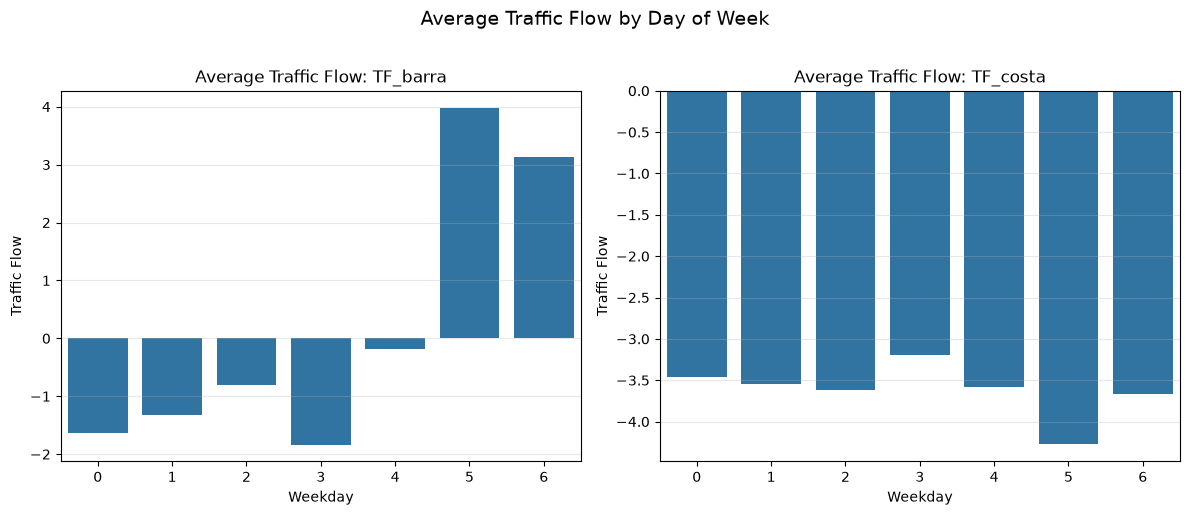

In [206]:
fig, axes = plt.subplots(1, len(tf_columns), figsize=(12, 5))

for ax, col in zip(axes, tf_columns):
    tf_wd_summary = (
        df.groupby("wd")[col]
        .mean()
        .reset_index()
    )
    
    sns.barplot(data=tf_wd_summary, x="wd", y=col, ax=ax)

    ax.set_title(f"Average Traffic Flow: {col}")
    ax.set_xlabel("Weekday")
    ax.set_ylabel("Traffic Flow")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Average Traffic Flow by Day of Week", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 2.2 Time series visualization

In [207]:
def plot_mean_med_speed(df_agg: pd.DataFrame, agg_by: str) -> None:
    plt.figure(figsize=(12, 6))
    
    plt.plot(df_agg.index, df_agg.values)
    
    plt.title(f"Mean Median Speed by {agg_by.capitalize()}")
    plt.xlabel(agg_by.capitalize())
    plt.ylabel("Mean Median Speed")
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    plt.legend(df_agg.columns, loc="upper right")
    plt.tight_layout()
    plt.show()

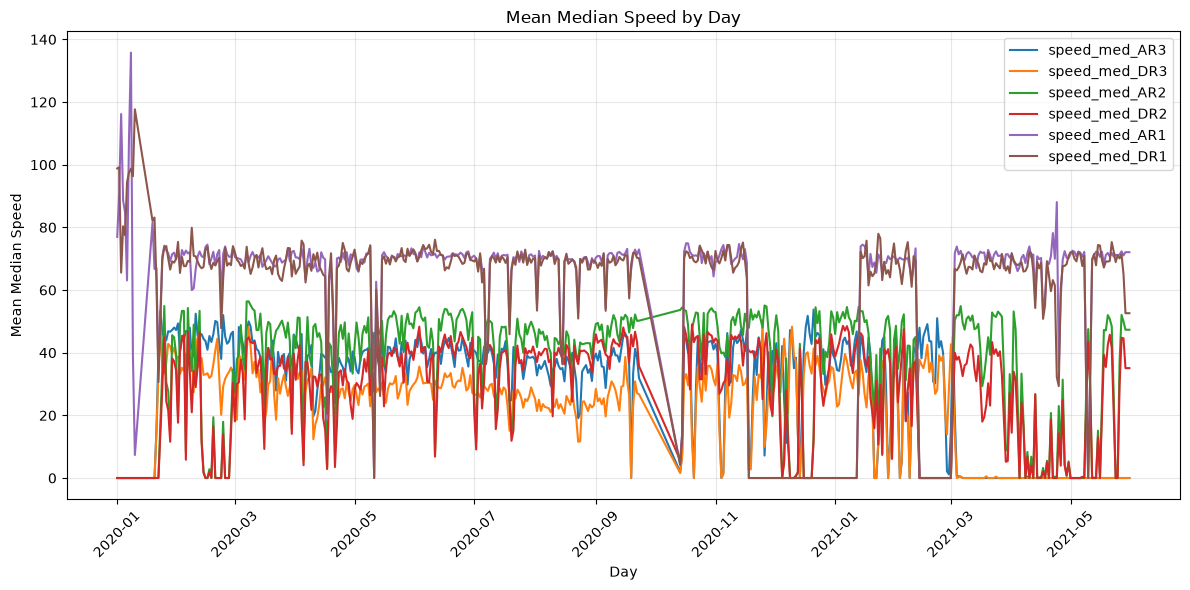

In [208]:
mean_med_speed_by_day = (
    df.groupby(df["timestamp"].dt.floor("D"))[speed_med_columns]
    .mean()
)
plot_mean_med_speed(mean_med_speed_by_day, agg_by="day")

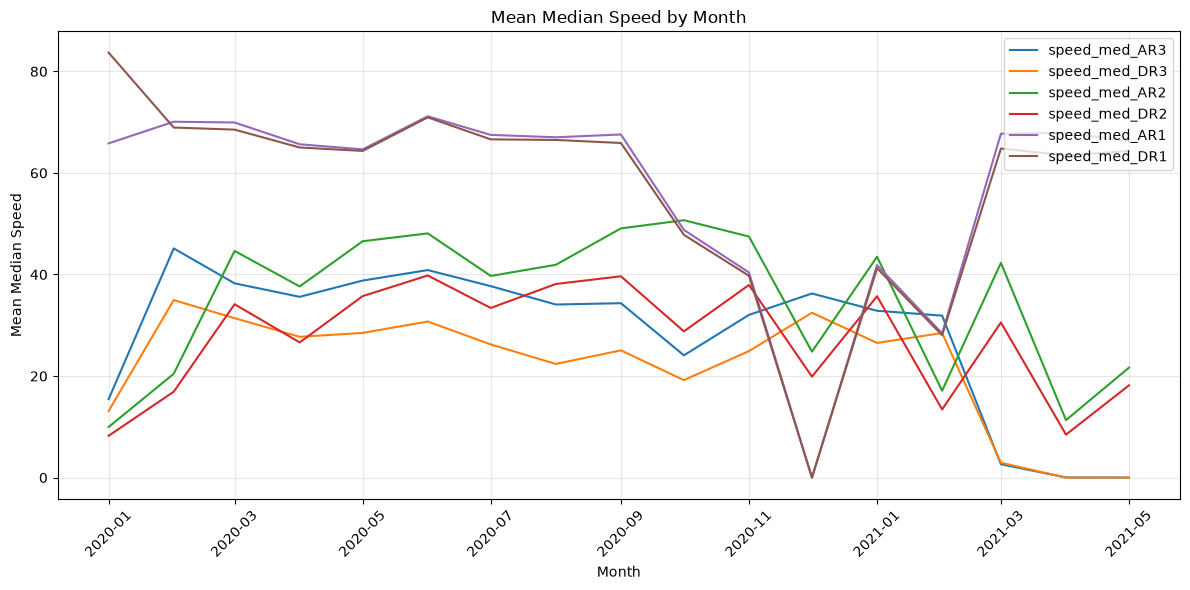

In [209]:
mean_med_speed_by_month = (
    df.groupby(df["timestamp"].dt.to_period('M'))[speed_med_columns]
    .mean()
)
mean_med_speed_by_month.index = mean_med_speed_by_month.index.to_timestamp()
plot_mean_med_speed(mean_med_speed_by_month, agg_by="month")

In [210]:
def plot_profile_plot(profile: pd.DataFrame, target: str) -> None:
    plt.figure(figsize=(12, 6))
    sns.lineplot(data=profile, x=target, y="value", 
                 hue="variable", marker="o")
    plt.xticks(range(profile[target].nunique()))
    plt.xlabel(target)
    plt.ylabel("Mean Median Speed")
    plt.title(f"Mean Speed by {target}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

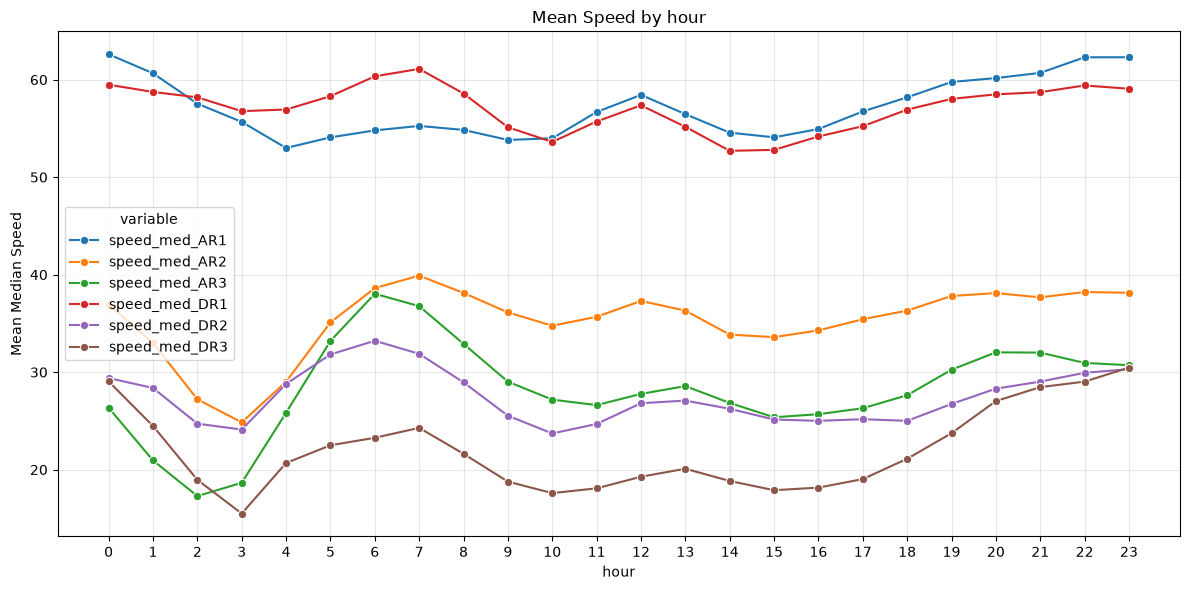

In [211]:
hourly_profile = (
    df_med_long.groupby(["hour", "variable"])["value"]
    .mean()
    .reset_index()
)
plot_profile_plot(hourly_profile, target="hour")

### 2.3 Correlation analysis and other heatmaps

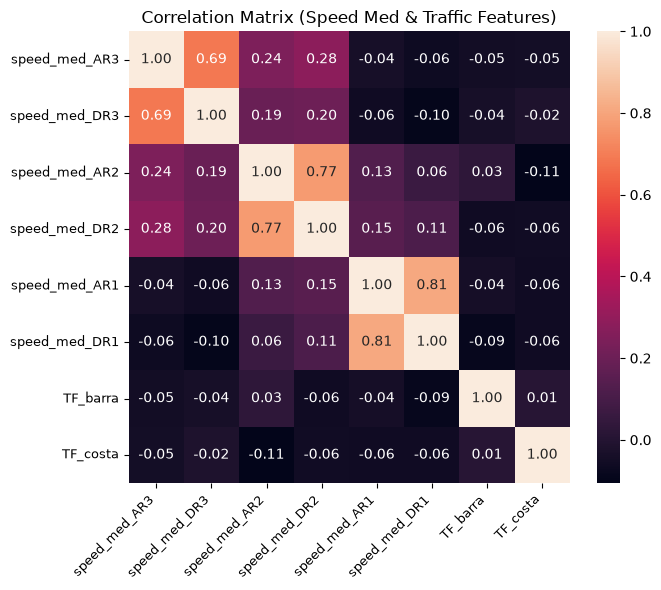

In [212]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[speed_med_columns + tf_columns].corr(),
            annot=True, fmt=".2f")

plt.title("Correlation Matrix (Speed Med & Traffic Features)")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

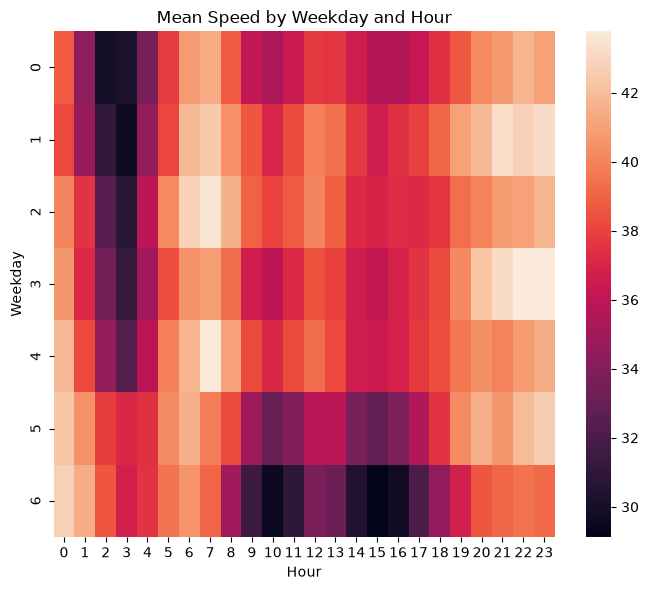

In [213]:
weekday_hour = (
    df_med_long.groupby(["wd", "hour"])["value"]
    .mean()
    .unstack("hour")
    .reindex(range(7))
)

plt.figure(figsize=(7, 6))
sns.heatmap(data=weekday_hour)
plt.title("Mean Speed by Weekday and Hour")
plt.xlabel("Hour")
plt.ylabel("Weekday")
plt.tight_layout()
plt.show()

## 3. Autocorrelation analysis

ACF / PACF

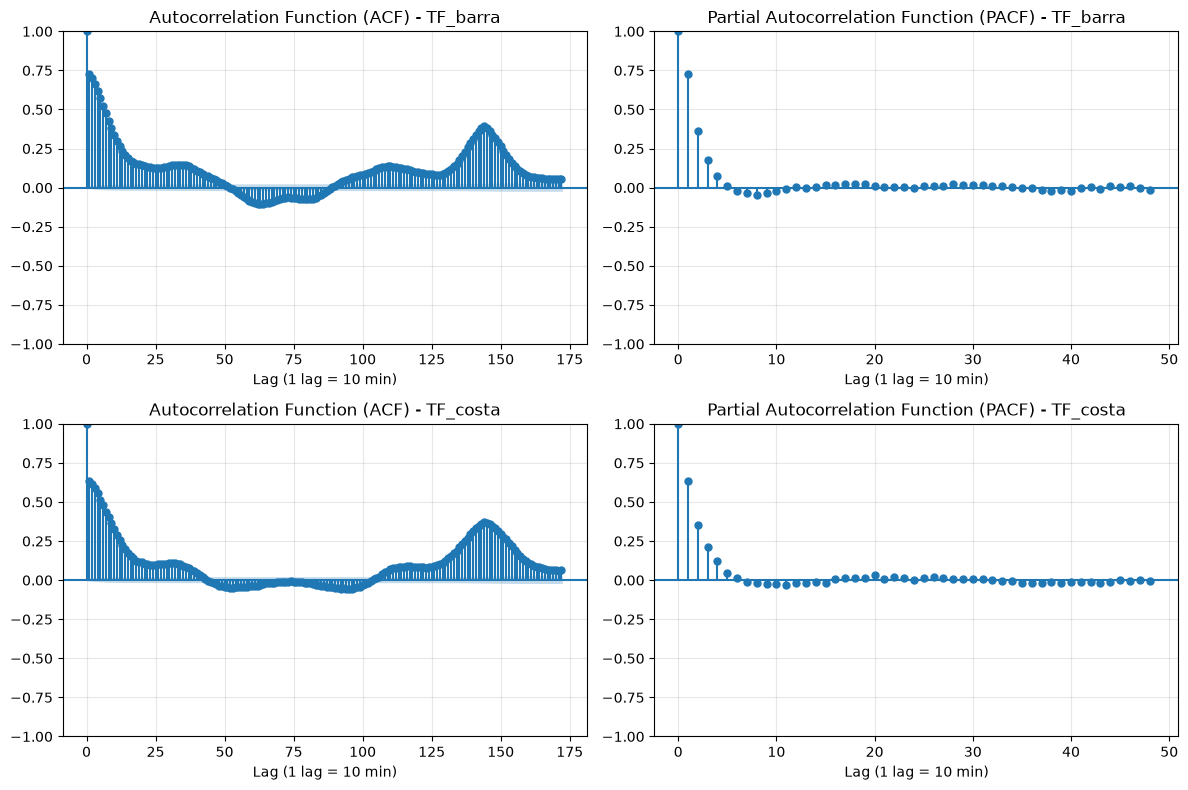

In [214]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

ts_data = df.set_index("timestamp")[tf_columns]
fig, axes = plt.subplots(len(tf_columns), 2, figsize=(12, 8))

for col, (ax1, ax2) in zip(tf_columns, axes):
    plot_acf(ts_data[col], lags=172, ax=ax1, alpha=0.05)
    ax1.set_title(f"Autocorrelation Function (ACF) - {col}")
    ax1.set_xlabel("Lag (1 lag = 10 min)")
    ax1.grid(True, alpha=0.3)

    plot_pacf(ts_data[col], lags=48, ax=ax2, alpha=0.05)
    ax2.set_title(f"Partial Autocorrelation Function (PACF) - {col}")
    ax2.set_xlabel("Lag (1 lag = 10 min)")
    ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Lags

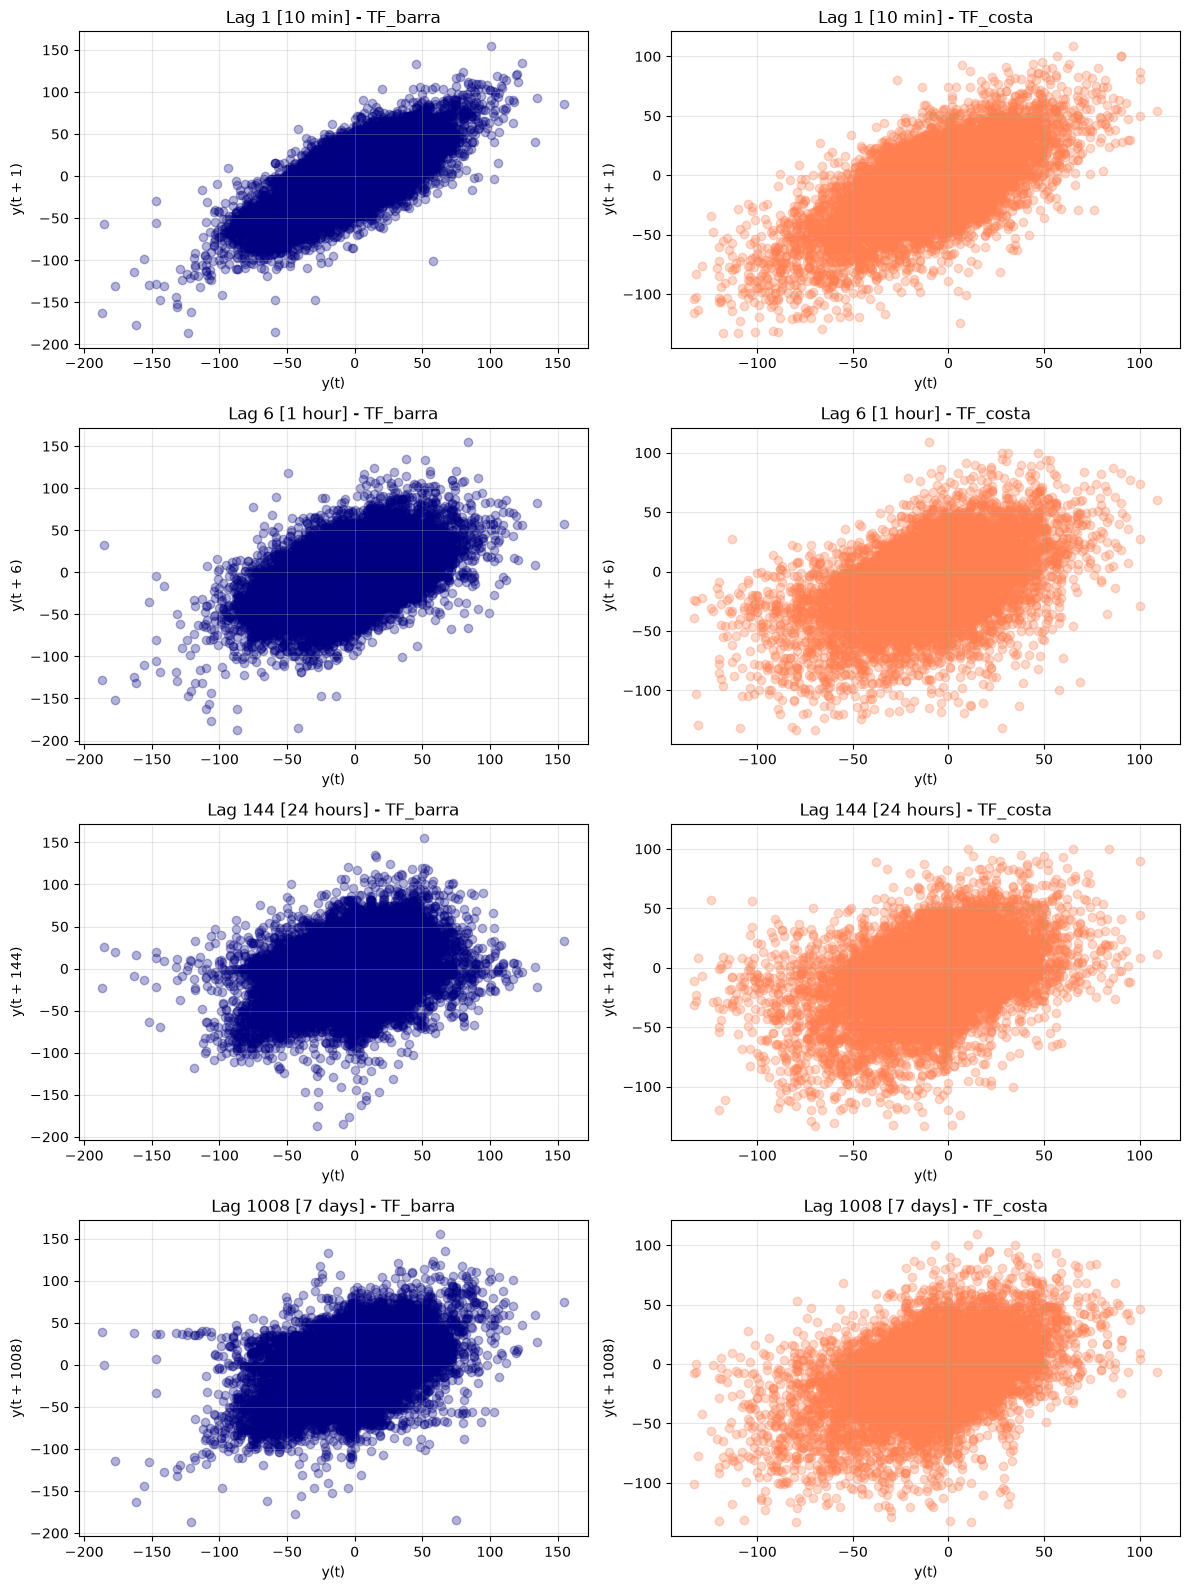

In [215]:
from pandas.plotting import lag_plot

LAG_LABELS = {
    1: "10 min",
    6: "1 hour",
    144: "24 hours",
    1008: "7 days"
}

fig, axes = plt.subplots(len(LAG_LABELS), 2, figsize=(12, len(LAG_LABELS) * 4))

for i, (lag, label) in enumerate(LAG_LABELS.items()):
    ax1, ax2 = axes[i]
    
    # TF_barra
    lag_plot(ts_data[tf_columns[0]], lag=lag, ax=ax1, c="navy", alpha=0.3)
    ax1.set_title(f"Lag {lag} [{label}] - {tf_columns[0]}")
    ax1.set_xlabel("y(t)")
    ax1.set_ylabel(f"y(t + {lag})")
    
    # TF_costa
    lag_plot(ts_data[tf_columns[1]], lag=lag, ax=ax2, c="coral", alpha=0.3)
    ax2.set_title(f"Lag {lag} [{label}] - {tf_columns[1]}")
    ax2.set_xlabel("y(t)")
    ax2.set_ylabel(f"y(t + {lag})")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [216]:
def lag_strength(series: pd.Series, nlags: int) -> np.ndarray:
    if len(series) <= nlags or series.std() == 0:
        return np.nan
    return sm.tsa.stattools.acf(series, nlags=nlags)[nlags]

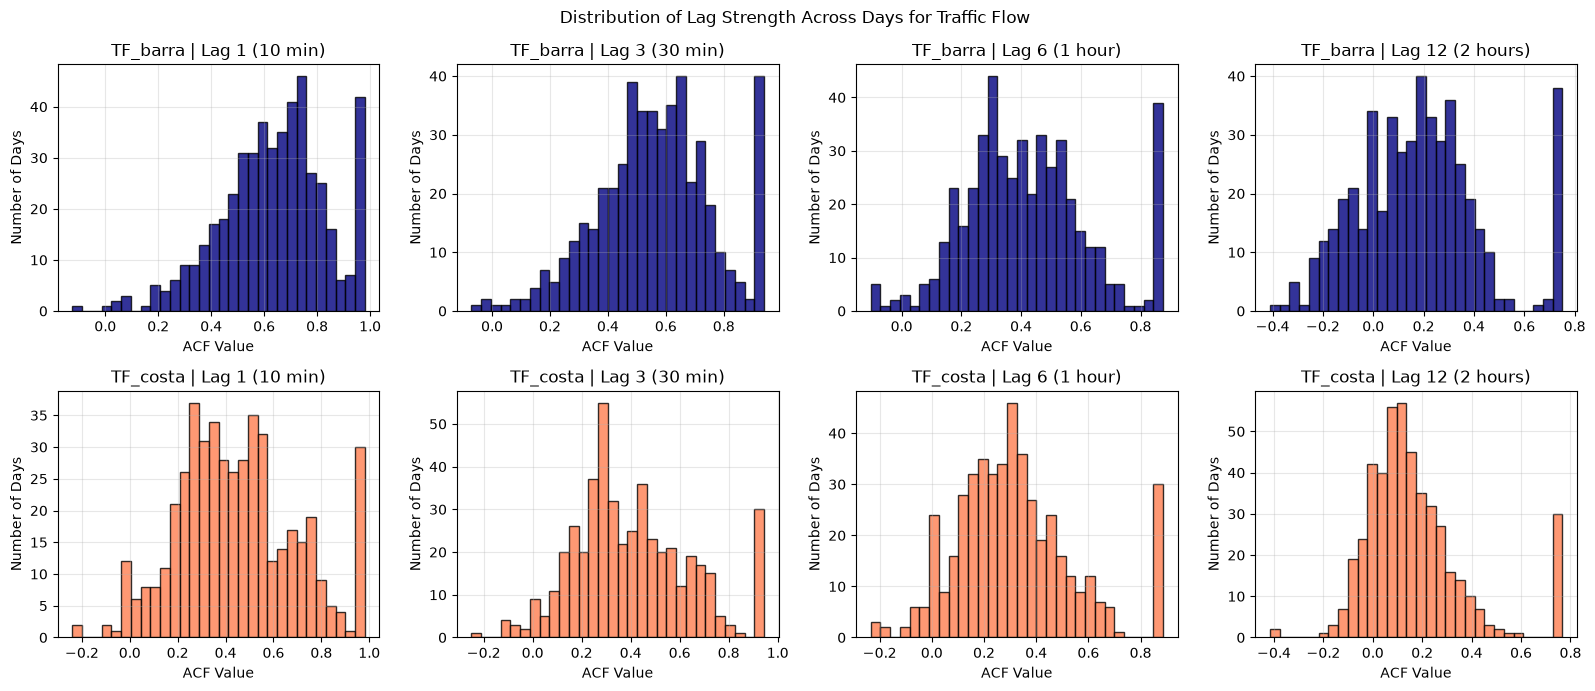

In [217]:
LAG_LABELS = {
    1: "10 min",
    3: "30 min",
    6: "1 hour",
    12: "2 hours"
}

daily_groups = [group for _, group in df.groupby(df["timestamp"].dt.date)]

fig, axes = plt.subplots(len(tf_columns), len(LAG_LABELS), 
                         figsize=(4*len(LAG_LABELS), 3.5*len(tf_columns)))

for i, col in enumerate(tf_columns):
    for j, (lag, label) in enumerate(LAG_LABELS.items()):
        lag_scores = [
            lag_strength(group[col].values, lag)
            for group in daily_groups
        ]
        lag_scores = pd.Series(lag_scores).dropna()

        ax = axes[i, j]
        ax.hist(
            lag_scores,
            bins=30,
            color="navy" if i == 0 else "coral",
            edgecolor="black",
            alpha=0.8,
        )
        ax.set_title(f"{col} | Lag {lag} ({label})")
        ax.set_xlabel("ACF Value")
        ax.set_ylabel("Number of Days")
        ax.grid(True, alpha=0.3)

plt.suptitle("Distribution of Lag Strength Across Days for Traffic Flow")
plt.tight_layout()
plt.show()

Volatility

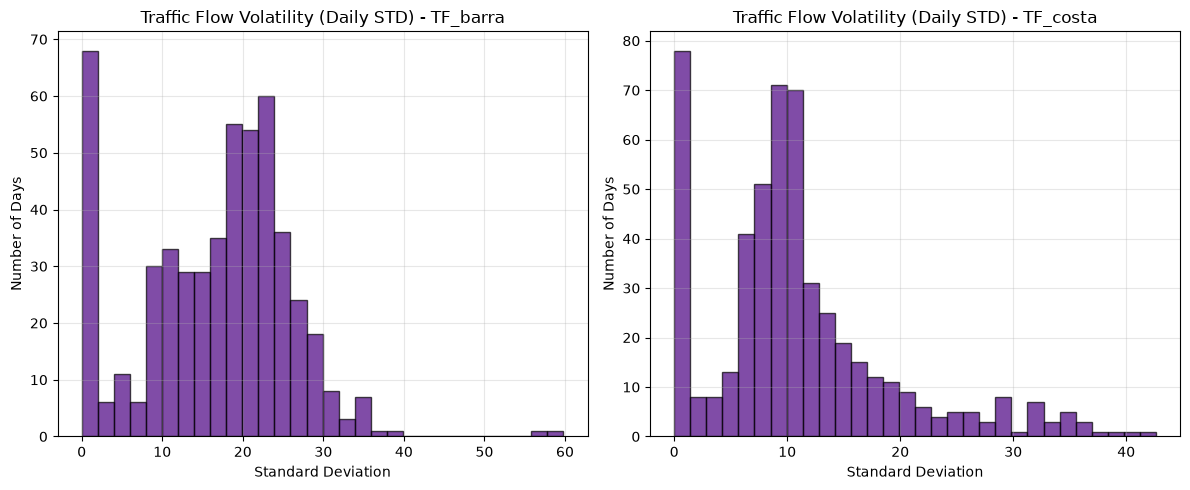

In [218]:
daily_tf_std = df.groupby(df["timestamp"].dt.date)[tf_columns].std()

fig, axes = plt.subplots(1, len(tf_columns), figsize=(12, 5))

for col, ax in zip(tf_columns, axes.flat):
    ax.hist(daily_tf_std[col], bins=30, color="indigo", alpha=0.7, edgecolor="black")
    ax.set_title(f"Traffic Flow Volatility (Daily STD) - {col}")
    ax.set_xlabel("Standard Deviation")
    ax.set_ylabel("Number of Days")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

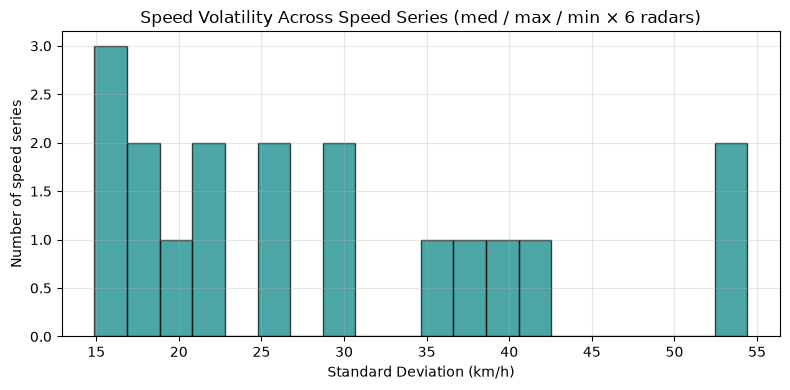

In [219]:
speed_volatility = df[speed_columns].std(axis=0)

plt.figure(figsize=(8, 4))
plt.hist(speed_volatility, bins=20, color="teal", alpha=0.7, edgecolor="black")
plt.title("Speed Volatility Across Speed Series (med / max / min × 6 radars)")
plt.xlabel("Standard Deviation (km/h)")
plt.ylabel("Number of speed series")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

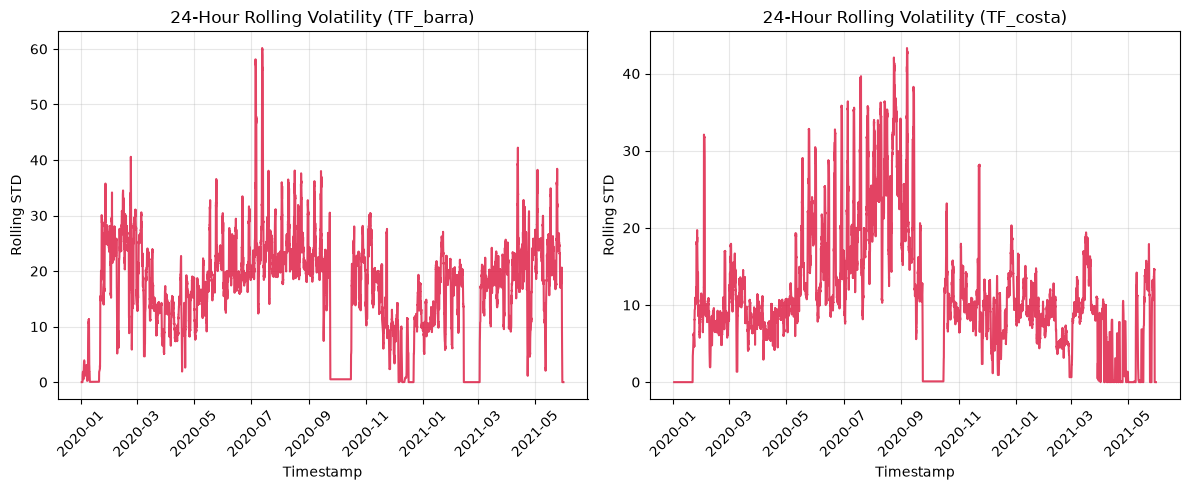

In [220]:
rolling_volatility = df.set_index("timestamp")[tf_columns].rolling(144).std()

fig, axes = plt.subplots(1, len(tf_columns), figsize=(12, 5))

for col, ax in zip(tf_columns, axes.flat):
    series = rolling_volatility[col]
    ax.plot(series.index, series, color="crimson", alpha=0.8)
    ax.set_title(f"24-Hour Rolling Volatility ({col})")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Rolling STD")
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Stationarity

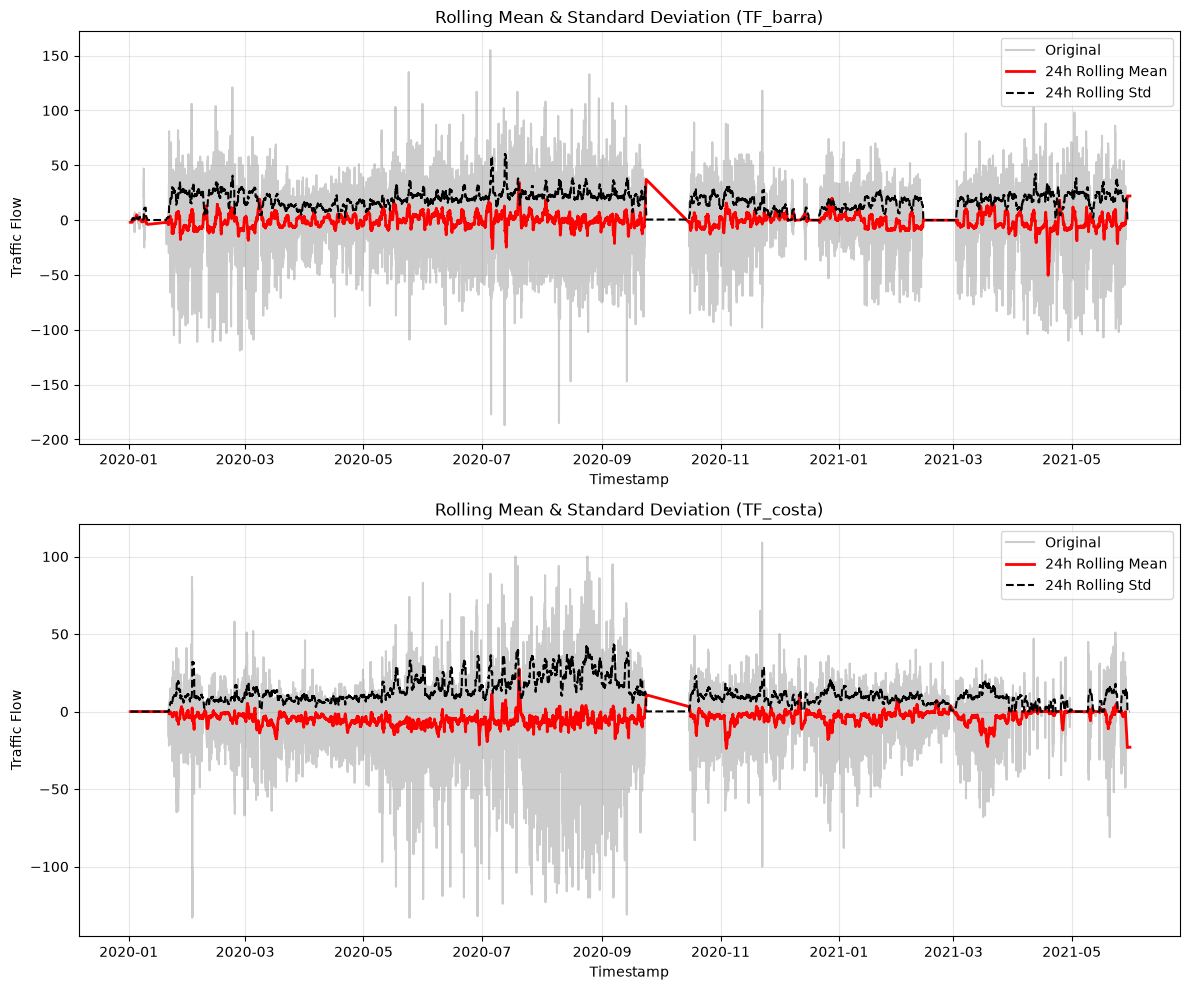

In [221]:
WINDOW_SIZE = 144

rolling_mean = ts_data.rolling(window=WINDOW_SIZE).mean()
rolling_std = ts_data.rolling(window=WINDOW_SIZE).std()

fig, axes = plt.subplots(len(tf_columns), 1, figsize=(12, 10))

for col, ax in zip(tf_columns, axes.flat):

    ax.plot(ts_data[col].index, ts_data[col], label=f"Original", alpha=0.4, color="gray")
    ax.plot(rolling_mean[col].index, rolling_mean[col], label="24h Rolling Mean", color="red", linewidth=2)
    ax.plot(rolling_std[col].index, rolling_std[col], label="24h Rolling Std", color="black", linestyle="--")

    ax.set_title(f"Rolling Mean & Standard Deviation ({col})")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Traffic Flow")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [222]:
from statsmodels.tsa.stattools import adfuller

for col in tf_columns:
    result = adfuller(df[col], autolag="AIC")
    adf_stat = result[0]
    p_value = result[1]

    print(f"--- ADF Test for: {col} ---")
    print(f"ADF Statistic: {adf_stat:.4f}")
    print(f"p-value: {p_value:.4f}\n")

--- ADF Test for: TF_barra ---
ADF Statistic: -34.8031
p-value: 0.0000

--- ADF Test for: TF_costa ---
ADF Statistic: -35.8240
p-value: 0.0000



## 4. Conclusions

### 4.1 Data structure and quality
- Dataset: **74,305 rows × 26 columns**, **10-minute** step, **2020-01-01 00:00 → 2021-05-31 00:00** (~517 days). No NaNs, no intervals longer than 10 min, the time grid is regular.
- Columns: time (`year…minute`, `wd`), `speed_{med,max,min}` for 6 radars (`AR1/DR1`, `AR2/DR2`, `AR3/DR3`), and two traffic flows, `TF_barra` and `TF_costa`.
- `wd` encoding: **0 = Monday … 6 = Sunday** (2020-01-01 was a Wednesday, `wd = 2`).
- **Missing data is masked rather than marked as NaN.** This is the main problem with the dataset:
  - long stretches of zeros or constants (early Jan 2020, ~20 Sep–15 Oct 2020, late Nov–early Dec 2020, ~10 Feb–1 Mar 2021, end of May 2021);
  - straight interpolation-like lines on the daily mean speed plot (Sep–Oct 2020);
  - ~30–40 days have ACF ≈ 0.9–1.0 at all lags, likely segments filled by interpolation or forward-fill;
  - 68–78 days (≈13–15 %) have a daily flow std ≈ 0 (dead sensor or constant data);
  - `AR3/DR3` are practically zero from March 2021, `AR2/DR2` degrade in April 2021, and `AR1/DR1` are ≈ 0 in December 2020.
- In early January 2020, `AR1/DR1` show anomalous daily means of 100–135 km/h, probably a filling artifact.

### 4.2 Speed
- Median speed distribution: **a huge spike at 0** (≈ 17 % of observations for `AR1/DR1`, ≈ 27 % for `AR2/DR2`, ≈ 33 % for `AR3/DR3`), then the bulk at 40–80 km/h and a heavy right tail up to ~190 km/h.
- The value **250** (`speed_med_AR2`, also `speed_max_*`) looks like a technical cap or an outlier.
- Radars split clearly into three groups:
  - **AR1/DR1**: fastest, mode ≈ 70 km/h, mean ≈ 55–60;
  - **AR2/DR2**: mode ≈ 50, mean ≈ 27–35;
  - **AR3/DR3**: slowest, bimodal, `DR3` median ≈ 15 km/h.
- Zeros probably mix "no vehicles" (night) with "sensor outage", so they should be separated.
- Correlation within a pair (AR↔DR) is high: **0.81** (site 1), **0.77** (site 2), **0.69** (site 3). Between neighbouring sites 2↔3 it is weak (0.19–0.28), and ≈ 0 for the other pairs.
- **There is no linear speed ↔ flow relationship** (|r| ≤ 0.11). The scatter plots show a nonlinear "funnel": high speeds (>100) occur only when flow ≈ 0 (free flow), while at large |TF| speed is squeezed into 20–70 km/h.

### 4.3 Traffic flow (`TF_barra`, `TF_costa`)
- Both variables are **signed** (negative values exist), symmetric around 0, with a peak at 0 and heavy Laplace-like tails (triangular shape on the log histogram).
- `TF_barra`: std ≈ 20.3, range −187…155, mean ≈ 0.2. `TF_costa`: std ≈ 14.5, range −133…109, mean ≈ −3.6, slightly left-skewed.
- This is probably a difference/balance between directions, but **the definition of the variable should be confirmed**.
- Day of week: `TF_barra` is on average positive on weekends (+3…+4) and negative on weekdays (−0.2…−1.8). `TF_costa` is negative every day, lowest on Saturday (≈ −4.3). The differences are small relative to the std, so the effect is weak.

### 4.4 Temporal patterns
- Daily speed profile (especially radars 2 and 3): minimum at **2–4 h**, morning peak at **6–7 h**, a small bump around 12 h, a dip at **14–16 h**, then growth until 22–23 h. Radars 1 are nearly flat (53–63 km/h). The night dip is probably partly caused by zeros.
- Weekday × hour: slowest on **Sunday 9–17 h** (≈ 29–31), fastest on Tue/Thu evenings (21–23 h) and in the morning peak at 6–7 h.
- Speed barely changes across days of the week (~2–5 km/h difference), with Sunday lowest at sites 2–3.
- Monthly and daily aggregates are **dominated by sensor outages**, not real seasonality. True seasonality cannot be estimated from these plots.

### 4.5 Autocorrelation and stationarity (TF)
- ACF decays quickly: lag-1 ≈ **0.72** (`barra`) and ≈ **0.63** (`costa`), nearly zero by ~50 lags (~8 h). **PACF cuts off after ~4–5 lags**, i.e. short memory, similar to AR(4–5).
- A clear **daily peak at lag 144** (≈ 0.4 / ≈ 0.37), plus smaller bumps around lags ~35 and ~110 (intra-day cycles). The weekly lag (1008) is weak but positive.
- Lag plots: 10 min and 1 h show a strong linear dependence, while 24 h and 7 days are much weaker.
- Per-day autocorrelation strength varies a lot (especially for `TF_costa`). Peaks near 1.0 correspond to interpolated or constant days, so **part of the "autocorrelation" is created by filling artifacts**.
- **Volatility is unstable**: `TF_costa` is noticeably higher in May–September 2020 (rolling std up to ~40), and `TF_barra` has spikes up to ~60 (July 2020). The series are therefore **heteroscedastic**.
- ADF: `TF_barra` −34.8, `TF_costa` −35.8, p < 0.0001, so the unit root is rejected and the series are stationary **in the mean**. However, ADF does not test seasonality or changing variance, and the zero segments artificially strengthen the result.

### 4.7 Implications for modeling
1. Separate "no data / sensor off" from real values and filter those segments out (or add a binary mask). Speed zeros should not be mixed with real observations.
2. Use only contiguous "healthy" segments for train/validation. `AR3/DR3` after March 2021 are unusable. Use chronological splits only.
3. Features: lags 1–5 (10–50 min), lag 144 (one day), `hour` / `wd` (cyclically encoded), the paired radar (AR↔DR).
4. Distributions are heavy-tailed and heteroscedastic, so robust losses (Huber / MAE) and/or scaling by rolling std are appropriate.
5. Because the linear speed ↔ flow dependence is weak, try nonlinear models (GBM, NN) or interaction features.